In [1]:
import os

import numpy as np
np.set_printoptions(suppress=True)  # 禁用科学计数
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 1. 看当前程序在哪个目录下运行
print("当前工作目录:", os.getcwd())

# 2. 看 data 文件夹里到底有哪些文件
if os.path.exists('data'):
    print("data文件夹内的文件:", os.listdir('data'))
else:
    print("警告：data 文件夹不存在！请检查是否在程序同一目录下")

当前工作目录: /Users/jethroming/Code/Machine_learning/LZH
data文件夹内的文件: ['西瓜数据集3.1.txt', '西瓜数据集alpha.txt']


In [3]:
path = 'data/西瓜数据集alpha.txt'  # 导入数据
data = pd.read_csv(path)
data.head()

,Density,Sugar content,Good melon
0,0.697,0.460,是
1,0.774,0.376,是
2,0.634,0.264,是
3,0.608,0.318,是
4,0.556,0.215,是


In [4]:
# 将'是', '否'换成'Y', 'N'
data['Good melon'][data['Good melon'].isin(['是'])] = 1
data['Good melon'][data['Good melon'].isin(['否'])] = 0
print(data.head())


   Density  Sugar content Good melon
0    0.697          0.460          1
1    0.774          0.376          1
2    0.634          0.264          1
3    0.608          0.318          1
4    0.556          0.215          1


/var/folders/b4/qwh98z_d37gg2_qygwhw2x900000gn/T/ipykernel_11441/334150530.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data['Good melon'][data['Good melon'].isin(['是'])] = 1
/var/folders/b4/qwh98z_d37gg2_qygwhw2x900000gn/T/ipykernel_

In [5]:
# 分离出 X 与 y
X = data.iloc[:, :2]
y = data.iloc[:, 2]
print(X)
print(y)

    Density  Sugar content
0     0.697          0.460
1     0.774          0.376
2     0.634          0.264
3     0.608          0.318
4     0.556          0.215
5     0.403          0.237
6     0.481          0.149
7     0.437          0.211
8     0.666          0.091
9     0.243          0.267
10    0.245          0.057
11    0.343          0.099
12    0.639          0.161
13    0.657          0.198
14    0.360          0.370
15    0.593          0.042
16    0.719          0.103
0     1
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
Name: Good melon, dtype: object


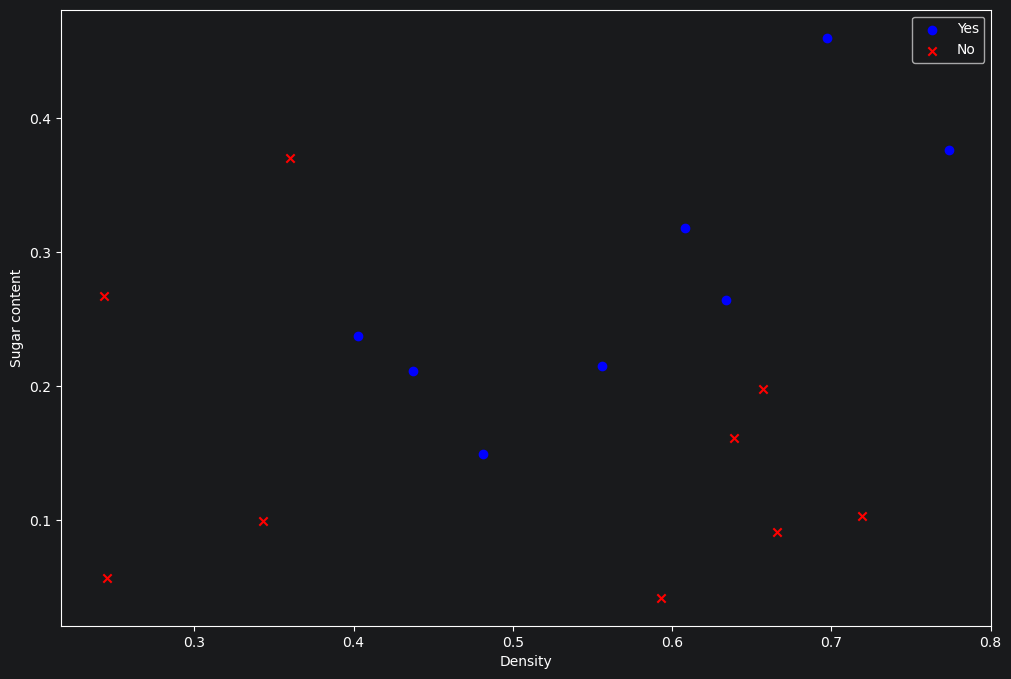

In [6]:
yes = data[data['Good melon'].isin([1])]
no = data[data['Good melon'].isin([0])]
fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(yes['Density'], yes['Sugar content'], marker='o', c='b', label='Yes')
ax.scatter(no['Density'], no['Sugar content'], marker='x', c='r', label='No')
ax.legend()
ax.set_xlabel('Density')
ax.set_ylabel('Sugar content')
plt.show()

In [18]:
"""
逻辑回归
Sigmoid函数
损失函数（对数似然）
求导，梯度
"""

'\n逻辑回归\nSigmoid函数\n损失函数（对数似然）\n求导，梯度\n'

In [7]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [8]:
def cost(params, X, y):
    beta = params[None].T
    res = np.multiply(-y, (X @ beta)) + np.log(1 + np.exp(X @ beta))
    return np.sum(res)

In [9]:
def gradient(params, X, y):
    beta = params[None].T
    grad = np.zeros([1, beta.shape[0]]).T  # 定义梯度数组存储梯度
    for i in range(beta.shape[0]):
        grad[i] = X.T[i][None] @ (sigmoid(X @ beta) - y)
    return grad.T[0]

In [10]:
params = np.array([1, 1, 1])
y_v = np.array([y], dtype=float).T
X_v = np.array(X)
X_v = np.insert(X_v, axis=1, values=np.ones(X_v.shape[0]), obj=2)  # 为了更方便的表示配置项, 添加值全 1 的项
gradient(params, X_v, y_v), cost(params, X_v, y_v)
beta_v = params.flatten()